# Search and Subscribe to AVUELO Datasets

## Overview

The Airborne Validation Unified Experiment: Land to Ocean ([AVUELO](https://www.earthdata.nasa.gov/data/projects/avuelo)) is a NASA airborne campaign co-led with the [Smithsonian Tropical Research Institute (STRI)](https://striresearch.si.edu/quantitative-forest-ecology/avuelo/) to improve understanding of biodiversity in tropical ecosystems and to validate spaceborne imaging spectroscopy over tropical forests and coastal waters.

In this tutorial, we will:

- find AVUELO datasets in [NASA Earthdata Search](https://search.earthdata.nasa.gov/) and set up email **subscriptions** to be notified of new data
- find the same datasets programmatically with the [`earthaccess`](https://earthaccess.readthedocs.io/) Python library

## Requirements

- A NASA [Earthdata Login](https://urs.earthdata.nasa.gov/) account. Subscriptions are sent to the email address on this account.
- See the [prerequisites](../../docs/prerequisites.md) page for setup instructions.

## AVUELO Datasets

The AVUELO datasets published so far are listed on the [AVUELO data access page](https://www.earthdata.nasa.gov/data/projects/avuelo/data-access-tools).

| Dataset | Short name | DOI |
|---|---|---|
| AVUELO AVIRIS-3 Orthocorrected Surface Reflectance (provisional calibration) | `AVUELO_AV3_L2A_Reflectance_2479` | [10.3334/ORNLDAAC/2479](https://doi.org/10.3334/ORNLDAAC/2479) |
| AVUELO: Tropical Forest Crown Maps with Tree Species Names, Panama | `TreeCrowns_Species_Panama_2517` | [10.3334/ORNLDAAC/2517](https://doi.org/10.3334/ORNLDAAC/2517) |
| AVIRIS-3 L1B Calibrated Radiance, Facility Instrument Collection | `AV3_L1B_RDN_2356` | [10.3334/ORNLDAAC/2356](https://doi.org/10.3334/ORNLDAAC/2356) |
| AVIRIS-3 L2B Greenhouse Gas Enhancements, Facility Instrument Collection | `AV3_L2B_GHG_2358` | [10.3334/ORNLDAAC/2358](https://doi.org/10.3334/ORNLDAAC/2358) |

The two AVIRIS-3 Facility Instrument collections (L1B radiance and L2B greenhouse gas) contain flights from all AVIRIS-3 campaigns, including AVUELO. The AVUELO L2A reflectance was produced with a **provisional calibration**. As noted in the [user guide](https://daac.ornl.gov/AVUELO/guides/AVUELO_AV3_L2A_Reflectance.html), an updated calibration is planned for the future. This is a good reason to set up a subscription. AVUELO UAVSAR radar data from 2026 are available here: https://www.earthdata.nasa.gov/data/instruments/uavsar.

## Part 1: NASA Earthdata Search

[NASA Earthdata Search](https://search.earthdata.nasa.gov/) is a web application to search, filter, and download data from all NASA Earth science data archives.

### Find AVUELO datasets

- *Step 1.* Go to https://search.earthdata.nasa.gov/search?q=AVUELO. The keyword `AVUELO` returns datasets whose metadata mention the campaign.
- *Step 2.* To filter by the campaign itself, expand the **Projects** facet in the left panel and check the box. Every dataset tagged with the AVUELO project is listed, including the AVIRIS-3 Facility Instrument collections and the UAVSAR collection.

![Earthdata Search for AVUELO](images/avuelo_edsearch.png)

- *Step 3.* Click a dataset, for example **AVUELO AVIRIS-3 Orthocorrected Surface Reflectance (provisional calibration)**, to see its granules (files) on a map. Click **(i)** next to the dataset title for its description, DOI, and links to the user guide.

![Granule Search for AVUELO](images/avuelo_edsearch_granules.png)

You can also go directly to the granules of a dataset with its concept ID, for example https://search.earthdata.nasa.gov/search/granules?p=C3906206748-ORNL_CLOUD for the AVUELO AVIRIS-3 reflectance.

### Subscribe to new data

Earthdata Search sends email notifications when new data match a saved search. There are two kinds of subscriptions:

- **Granule subscriptions** notify you when new granules (files) are added to a dataset. You can limit them to your area and time of interest.
- **Dataset subscriptions** notify you when new datasets matching your search are published, for example a new AVUELO dataset or the planned version 2 AVIRIS-3 reflectance.

#### Granule Subscription
To create a **granule subscription**:

- *Step 1.* Log in to [Earthdata Search](https://search.earthdata.nasa.gov/) with your Earthdata Login.
- *Step 2.* Open the granules of a dataset, for example the [AVUELO AVIRIS-3 reflectance](https://search.earthdata.nasa.gov/search/granules?p=C3906206748-ORNL_CLOUD).
3. Optionally, draw or upload your area of interest (spatial filter) and set a temporal filter. The subscription only notifies you about granules that match these filters.

![Granule Subscription based on spatiotemporal filter](images/avuelo_granule_subscription.png)

- *Step 3.* Click **Subscriptions** in the granule results panel.
- *Step 4.* Give the subscription a name, review the query, and click **Create Subscription**.

![Granule Subscription based on spatiotemporal filter](images/avuelo_granule_subscription_form.png)

#### Dataset Subscription

To create a **dataset subscription**:

- *Step 1.* Search for datasets, for example with the `AVUELO` project facet checked.
- *Step 2.* Click **Subscriptions** at the bottom of the dataset results list.
- *Step 3.* Give the subscription a name and click **Create Subscription**.

Notifications go to the email address on your Earthdata Login profile. To view, edit, or delete your subscriptions, click your username in the top right of Earthdata Search and choose [**Subscriptions**](https://search.earthdata.nasa.gov/subscriptions).

## Part 2: Search with `earthaccess`

The `earthaccess` Python library searches NASA's [Common Metadata Repository (CMR)](https://cmr.earthdata.nasa.gov/search/site/docs/search/api.html), the catalog behind Earthdata Search. It can also stream and download data.

### Import libraries

In [1]:
import json
from datetime import datetime, timezone
import earthaccess
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

### Authentication

`earthaccess.login()` authenticates with your Earthdata Login credentials. If you have a `.netrc` file or `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` environment variables, login completes without a prompt. Searching does not require login, but streaming and downloading data do.

In [2]:
auth = earthaccess.login()

### Search datasets by project

Every dataset in CMR has a list of projects (campaigns) in its metadata. We use `project='AVUELO'` to find all datasets tagged with the AVUELO campaign.

In [3]:
collections = earthaccess.search_datasets(project='AVUELO')
print(f"Datasets found: {len(collections)}")

Datasets found: 5


We put the main metadata of each dataset in a table. Here we read the UMM (Unified Metadata Model) records directly so the code works across `earthaccess` versions.

In [4]:
def collection_details(c):
    """Returns dataset metadata as a dictionary."""
    umm = c['umm']
    temporal = umm['TemporalExtents'][0]['RangeDateTimes'][0]
    return {
        'short_name': umm['ShortName'],
        'title': umm['EntryTitle'],
        'doi': c.doi,
        'concept_id': c.concept_id,
        'start': temporal.get('BeginningDateTime', '')[:10],
        'end': temporal.get('EndingDateTime', 'present')[:10],
    }

pd.set_option('display.max_colwidth', 80)
df = pd.DataFrame([collection_details(c) for c in collections])
df

,short_name,title,doi,concept_id,start,end
0,AV3_L1B_RDN_2356,"AVIRIS-3 L1B Calibrated Radiance, Facility Instrument Collection",10.3334/ORNLDAAC/2356,C3236537162-ORNL_CLOUD,2023-07-05,present
1,AV3_L2B_GHG_2358,"AVIRIS-3 L2B Greenhouse Gas Enhancements, Facility Instrument Collection",10.3334/ORNLDAAC/2358,C3236537512-ORNL_CLOUD,2023-07-05,present
2,AVUELO_AV3_L2A_Reflectance_2479,AVUELO AVIRIS-3 Orthocorrected Surface Reflectance (provisional calibration),10.3334/ORNLDAAC/2479,C3906206748-ORNL_CLOUD,2025-02-06,2025-02-28
3,TreeCrowns_Species_Panama_2517,"AVUELO: Tropical Forest Crown Maps with Tree Species Names, Panama",10.3334/ORNLDAAC/2517,C4266301156-ORNL_CLOUD,2023-04-13,2026-02-21
4,UAVSAR_POLSAR,UAVSAR Polarimetric Synthetic Aperture Radar (PolSAR) Product,10.5067/7PEQV8SVR4DM,C4261555796-ASF,2008-07-24,present


The AVUELO-only datasets (reflectance and tree crowns) cover the campaign period. The AVIRIS-3 Facility Instrument collections and UAVSAR span many campaigns.

A free-text `keyword` search is broader. It also matches datasets that only mention the keyword in their description.

In [5]:
keyword_results = earthaccess.search_datasets(project='AVUELO',
                                              keyword='UAVSAR')
[c['umm']['ShortName'] for c in keyword_results]

['UAVSAR_POLSAR']

### Dataset details

Each dataset has an abstract, a citation, and links to its user guide. Here are the details of the AVUELO AVIRIS-3 reflectance, which we find by its DOI.

In [6]:
c = earthaccess.search_datasets(doi='10.3334/ORNLDAAC/2479')[0]
print(f"Citation:\n {c.citation(format='apa', language='en-US')}")
print(f"Abstract:\n {c.abstract}")
print(f"Summary:\n {json.dumps(c.summary, indent=4)}")

Citation:
 Brodrick, P. G., Chlus, A. M., Eckert, R., Chapman, J. W., Eastwood, M., Geier, S., Lundeen, S. R., Olson-Duvall, W., Rios, L. M., Jensen, D. J., Bernas, M., Thompson, D. R., & Green, R. O. (2025). AVUELO AVIRIS-3 Orthocorrected Surface Reflectance (provisional calibration) (Version 1). ORNL Distributed Active Archive Center. https://doi.org/10.3334/ORNLDAAC/2479

Abstract:
 This dataset contains Level 2A (L2A) orthocorrected surface reflectance and uncertainty estimates from the Airborne Visible / Infrared Imaging Spectrometer-3 (AVIRIS-3) instrument acquired for the Airborne Validation Unified Experiment: Land to Ocean (AVUELO) project in 2025. This L2A data product was generated with a provisional calibration algorithm.  AVUELO aims to advance the validation and calibration of spaceborne imaging spectroscopy (hyperspectral) data for tropical ecosystems by combining airborne imaging spectroscopy for terrestrial and marine sites in Panama and Costa Rica with contemporaneous

### Granule count

We count the granules in each AVIRIS-3 dataset with `hits()`, which asks CMR for a count without downloading the metadata. For the multi-campaign AVIRIS-3 collections, we restrict the count to the AVUELO flight period (6–28 February 2025) and the campaign bounding box over Panama and Costa Rica.

In [7]:
# AVUELO 2025 campaign period and bounding box (west, south, east, north)
avuelo_temporal = ('2025-02-06', '2025-02-28')
avuelo_bbox = (-85.71, 7.14, -79.32, 10.92)

counts = []
for c in collections:
    short_name = c['umm']['ShortName']
    if not short_name.startswith('AV'):
        continue  # count AVIRIS-3 datasets only
    query = earthaccess.DataGranules().short_name(short_name)
    total = query.hits()
    in_avuelo = query.temporal(*avuelo_temporal).bounding_box(*avuelo_bbox).hits()
    counts.append({'short_name': short_name,
                   'all_granules': total,
                   'avuelo_2025_granules': in_avuelo})
pd.DataFrame(counts)

,short_name,all_granules,avuelo_2025_granules
0,AV3_L1B_RDN_2356,21501,1772
1,AV3_L2B_GHG_2358,21266,1762
2,AVUELO_AV3_L2A_Reflectance_2479,3530,3530


### Summarize the AVIRIS-3 flights

Next, we get the metadata of all AVUELO AVIRIS-3 reflectance granules. Each scene has two files, and each file is a separate granule in CMR:

| Product | Contents |
|---|---|
| `RFL_ORT` | Orthorectified surface reflectance, aerosol optical thickness, and water vapor |
| `UNC_ORT` | Reflectance uncertainty (one standard deviation) |

File names follow the pattern `AV3YYYYMMDDthhmmss_<scene>_L2A_OE_<version>_<product>.nc`. `AV3YYYYMMDDthhmmss` identifies the **flight line** by its start date and time (UTC), and `<scene>` is the scene number along the flight line.

In [8]:
shortname = 'AVUELO_AV3_L2A_Reflectance_2479'
granules = earthaccess.search_data(short_name=shortname)
print(f"Granules found: {len(granules)}")

Granules found: 3530


We create a geopandas dataframe from the granule search results above.

In [9]:
def granule_details(g):
    """Returns AVIRIS-3 granule metadata as a dictionary."""
    name = g['umm']['GranuleUR'].split('.', 1)[1]
    parts = name.split('_')
    return {
        'granule': name,
        'flight_line': parts[0],
        'scene': parts[1],
        'product': '_'.join(parts[-2:]).removesuffix('.nc'),
        'start_time': pd.to_datetime(g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime']),
        'size_mb': g['size'],
    }

gdf = gpd.GeoDataFrame([granule_details(g) for g in granules],
                       geometry=gpd.GeoSeries(granules, crs='EPSG:4326'))
gdf['date'] = gdf.start_time.dt.date
gdf.head()

,granule,flight_line,scene,product,start_time,size_mb,geometry,date
0,AV320250206t174741_000_L2A_OE_5988d8f5_RFL_ORT.nc,AV320250206t174741,000,RFL_ORT,2025-02-06 17:47:55+00:00,1019.457613,"MULTIPOLYGON (((-79.8222 9.40398, -79.7708 9.40398, -79.7708 9.45912, -79.82...",2025-02-06
1,AV320250206t174741_000_L2A_OE_5988d8f5_UNC_ORT.nc,AV320250206t174741,000,UNC_ORT,2025-02-06 17:47:55+00:00,1119.645211,"MULTIPOLYGON (((-79.8222 9.40398, -79.7708 9.40398, -79.7708 9.45912, -79.82...",2025-02-06
2,AV320250206t174741_001_L2A_OE_5988d8f5_UNC_ORT.nc,AV320250206t174741,001,UNC_ORT,2025-02-06 17:48:30+00:00,1111.486578,"MULTIPOLYGON (((-79.7967 9.38028, -79.7454 9.38028, -79.7454 9.434, -79.7967...",2025-02-06
3,AV320250206t174741_001_L2A_OE_5988d8f5_RFL_ORT.nc,AV320250206t174741,001,RFL_ORT,2025-02-06 17:48:30+00:00,1004.240316,"MULTIPOLYGON (((-79.7967 9.38028, -79.7454 9.38028, -79.7454 9.434, -79.7967...",2025-02-06
4,AV320250206t174741_002_L2A_OE_5988d8f5_UNC_ORT.nc,AV320250206t174741,002,UNC_ORT,2025-02-06 17:49:06+00:00,1100.787710,"MULTIPOLYGON (((-79.7711 9.35486, -79.7207 9.35486, -79.7207 9.40947, -79.77...",2025-02-06


We tabulate the number of flight lines and scenes by date.

In [10]:
summary = (gdf[gdf['product'] == 'RFL_ORT']
           .groupby('date')
           .agg(flight_lines=('flight_line', 'nunique'), scenes=('scene', 'size')))
summary['size_gb'] = (gdf.groupby('date').size_mb.sum() / 1024).round(1)
print(f"Flight lines: {gdf.flight_line.nunique()}, scenes: {summary.scenes.sum()}, "
      f"total size: {summary.size_gb.sum():.0f} GB")
summary

Flight lines: 179, scenes: 1765, total size: 3987 GB


,flight_lines,scenes,size_gb
date,,,
2025-02-06,17,215,486.6
2025-02-08,22,110,270.7
2025-02-10,14,203,451.3
2025-02-11,20,163,386.9
2025-02-17,10,67,142.0
2025-02-19,24,201,466.5
2025-02-22,25,206,477.1
2025-02-24,8,129,266.5
2025-02-25,13,172,371.7


We plot the number of scenes by date.

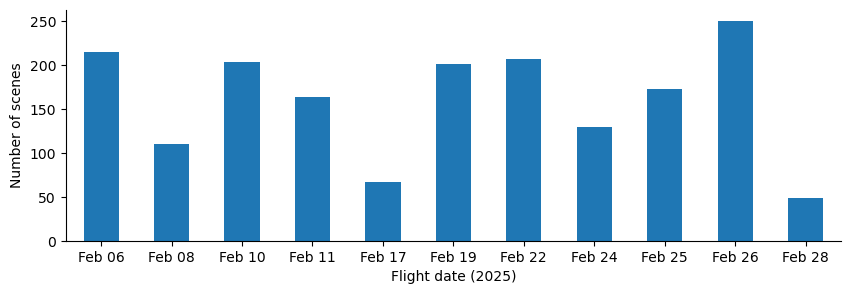

In [11]:
ax = summary.scenes.plot.bar(figsize=(10, 3))
ax.set_xlabel('Flight date (2025)')
ax.set_ylabel('Number of scenes')
ax.set_xticklabels([d.strftime('%b %d') for d in summary.index], rotation=0)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The map below shows the bounding box of each scene, colored by flight date. 

In [12]:
rfl_gdf = gdf[gdf['product'] == 'RFL_ORT'].copy()
rfl_gdf['date'] = rfl_gdf['date'].astype(str)
rfl_gdf.explore(column='date', cmap='tab20', tiles=xyz, attr=attr,
                tooltip=['granule', 'start_time'],
                style_kwds={'fillOpacity': 0.1, 'weight': 1})

### Export the granules boundary

We can optionally export the granule boundary into a GIS format such as geojson, kml, geopackage, or shapefile for further analysis in a desktop GIS.

In [13]:
## exporting to external files
# rfl_gdf.to_file(f"data/{shortname}_granules.geojson", driver="GeoJSON")
# rfl_gdf.to_file(f"data/{shortname}_granules.shp", driver="ESRI Shapefile")
# rfl_gdf.to_file(f"data/{shortname}_granules.kml", driver="LIBKML")
rfl_gdf.to_file(f"data/{shortname}_granules.gpkg", driver="GPKG")